# Session 30 Solutions: Hyperparameter Tuning

Data Science with Python, Level 2, Stage 4: Applied ML

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     train_test_split, cross_val_score)
from sklearn.metrics import roc_auc_score

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
y = (churn["churn"] == "Yes").astype(int)
X = churn.drop(columns=["customer_id", "churn"])
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2,
                                                stratify=y, random_state=0)
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                          OneHotEncoder(handle_unknown="ignore")),
     make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
pipe = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))])

## In-Class Exercises

### In-Class Exercise 1: Tune a Tree

In [2]:
from sklearn.tree import DecisionTreeClassifier
tree_pipe = Pipeline([("prep", preprocess), ("model", DecisionTreeClassifier(random_state=0))])
grid = {"model__max_depth": list(range(2, 11)), "model__min_samples_leaf": [1, 10, 50]}
s = GridSearchCV(tree_pipe, grid, cv=5, scoring="roc_auc").fit(X_dev, y_dev)
print(s.best_params_, round(s.best_score_, 4))

{'model__max_depth': 3, 'model__min_samples_leaf': 50} 0.7468


### In-Class Exercise 2: Heatmap of a Grid

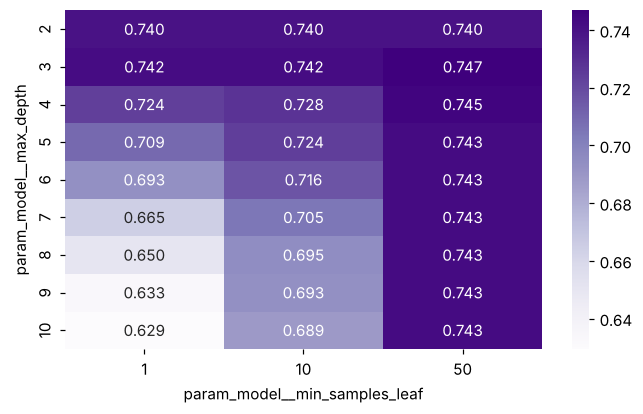

In [3]:
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
tree_pipe = Pipeline([("prep", preprocess), ("model", DecisionTreeClassifier(random_state=0))])
grid = {"model__max_depth": list(range(2, 11)), "model__min_samples_leaf": [1, 10, 50]}
s = GridSearchCV(tree_pipe, grid, cv=5, scoring="roc_auc").fit(X_dev, y_dev)
r = pd.DataFrame(s.cv_results_)
table = r.pivot_table(index="param_model__max_depth", columns="param_model__min_samples_leaf", values="mean_test_score")
sns.heatmap(table, annot=True, fmt=".3f", cmap="Purples")
plt.show()

### In-Class Exercise 3: Forest Random Search

In [4]:
rf_pipe = Pipeline([("prep", preprocess), ("model", RandomForestClassifier(random_state=0, n_jobs=-1))])
space = {"model__n_estimators": randint(100, 500), "model__max_depth": [4, 8, 12, None], "model__min_samples_leaf": randint(1, 50), "model__max_features": ["sqrt", 0.5, 1.0]}
s = RandomizedSearchCV(rf_pipe, space, n_iter=20, cv=5, scoring="roc_auc", random_state=0).fit(X_dev, y_dev)
print(s.best_params_, round(s.best_score_, 4))

{'model__max_depth': 4, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 13, 'model__n_estimators': 414} 0.7761


### In-Class Exercise 4: Tune for Recall

In [5]:
p = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))])
grid = {"model__C": [0.01, 0.1, 1], "model__class_weight": [None, "balanced"]}
s = GridSearchCV(p, grid, cv=5, scoring="recall").fit(X_dev, y_dev)
print(s.best_params_, round(s.best_score_, 3))
# Recall rewards flagging more leavers, so the balanced class weight wins clearly.

{'model__C': 1, 'model__class_weight': 'balanced'} 0.769


## Part A: Basic

### Exercise 1: Count the Fits

In [6]:
fits = 5 * 2 * 2 * 5 + 1
print(fits)

101


### Exercise 2: Validation Curve by Hand

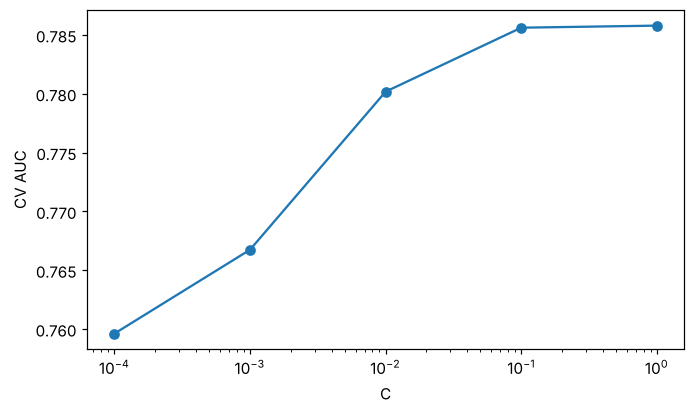

In [7]:
p = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))])
Cs = [0.0001, 0.001, 0.01, 0.1, 1]
scores = [cross_val_score(p.set_params(model__C=c), X_dev, y_dev, cv=5, scoring="roc_auc").mean() for c in Cs]
plt.plot(Cs, scores, marker="o")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("CV AUC")
plt.show()

## Part B: Intermediate

### Exercise 3: Tune a Price Model

In [8]:
from sklearn.linear_model import Ridge
flats = pd.read_csv(DATA_URL + "apartments.csv")
Xa = flats.drop(columns=["apartment_id", "price_k"])
pre = ColumnTransformer([
    ("num", StandardScaler(), make_column_selector(dtype_include="number")),
    ("cat", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
s = GridSearchCV(Pipeline([("prep", pre), ("model", Ridge())]), {"model__alpha": np.logspace(-3, 3, 13)}, cv=5, scoring="neg_mean_absolute_error").fit(Xa, flats["price_k"])
print(round(s.best_params_["model__alpha"], 3), round(-s.best_score_, 2))

1.0 9.98


### Exercise 4: K for K-Means? No, K for Neighbours

K nearest neighbours predicts from the most similar customers. It needs scaled features, which the pipeline already provides.

In [9]:
from sklearn.neighbors import KNeighborsClassifier
p = Pipeline([("prep", preprocess), ("model", KNeighborsClassifier())])
s = GridSearchCV(p, {"model__n_neighbors": [5, 15, 31, 51, 101], "model__weights": ["uniform", "distance"]}, cv=5, scoring="roc_auc").fit(X_dev, y_dev)
print(s.best_params_, round(s.best_score_, 4))

{'model__n_neighbors': 101, 'model__weights': 'uniform'} 0.7613


## Part C: Challenge

### Exercise 5: Is the Gain Real?

In [10]:
from sklearn.model_selection import StratifiedKFold
folds = StratifiedKFold(10, shuffle=True, random_state=1)
default = Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(random_state=0))])
tuned = Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(learning_rate=0.011, max_depth=6, max_iter=247, min_samples_leaf=89, l2_regularization=0.087, random_state=0))])
a = cross_val_score(default, X_dev, y_dev, cv=folds, scoring="roc_auc")
b = cross_val_score(tuned, X_dev, y_dev, cv=folds, scoring="roc_auc")
diff = b - a
print(diff.round(3), round(diff.mean(), 3), round(diff.std(), 3))

[0.065 0.071 0.055 0.043 0.067 0.024 0.039 0.093 0.042 0.036] 0.053 0.019


## Part D: Cumulative Project: Customer Churn

### Exercise 6: Customer Churn: Step 7, Tune Two Candidates

In [11]:
log_s = GridSearchCV(Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))]), {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}, cv=5, scoring="roc_auc").fit(X_dev, y_dev)
space = {"model__learning_rate": loguniform(0.01, 0.3), "model__max_depth": [2, 3, 4, 6], "model__max_iter": randint(50, 400), "model__min_samples_leaf": randint(10, 100)}
boost_s = RandomizedSearchCV(Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(random_state=0))]), space, n_iter=20, cv=5, scoring="roc_auc", random_state=0, n_jobs=-1).fit(X_dev, y_dev)
rows = []
for name, s in [("logistic", log_s), ("boosting", boost_s)]:
    r = s.cv_results_
    rows.append({"model": name, "cv_auc": round(s.best_score_, 4), "std": round(r["std_test_score"][s.best_index_], 4)})
pd.DataFrame(rows)
# Logistic regression is as good or better, simpler and easier to explain, so it is the choice.

,model,cv_auc,std
0,logistic,0.7863,0.0122
1,boosting,0.7777,0.0137


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | We choose it before training. |
| 2 | C | 4 x 3 x 5 = 60. |
| 3 | B | It samples a fixed budget of combinations. |
| 4 | B | refit=True is the default. |
| 5 | B | The gain is far smaller than the variation. |